# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

## Setup

In [1]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.

    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]
    """
    
    app_folder_name = "lid-driven-cavity"

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    if source_lang == "CUDA":
        code_compiler = "nvcc"
        code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"
        # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
        # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto1preview"  # (max token = 128000)
    model_coder = "gpto1preview"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)

    # -- FROM OLLAMA
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "03test_o1p_ee_context_fewsht_compare"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, code_compiler, code_compiler_kwds, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: lid-driven-cavity

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto1preview
Model coder: gpto1preview
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto1preview/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp03test_o1p_ee_context_fewsht_compare

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

LLM Prompt for Code Generation: 

Carefully follow all these instructions step-by-step: 
STEP 1. Read the background knowledge and your background knowledge summaries about programming and energy-efficiency strategies. 
STEP 2. Read your descripti

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 21.103580 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


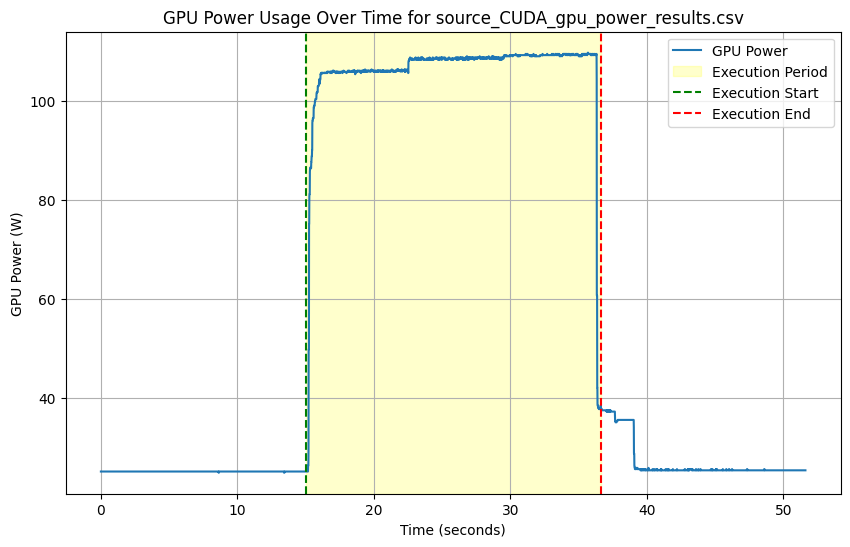

Start time: 15.001 -- End time: 36.626

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 21.63 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000638 kWh
  0.6375 Wh
  2295.05 J
Average GPU power: 106.19 W
Total Energy During Exe Runtime:   2295.05 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 21.63
GPU power data has been written to idle__gpu_power_results.csv


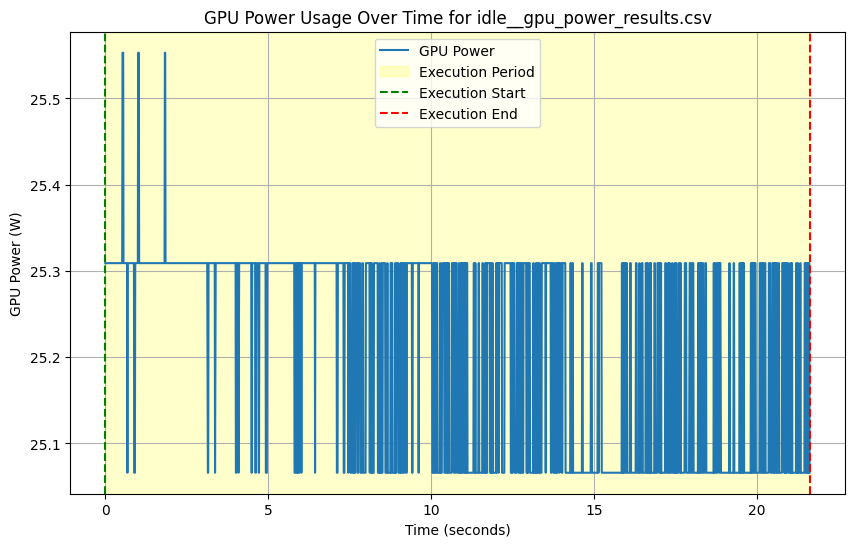

Start time: 0 -- End time: 21.626

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 21.63 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000151 kWh
  0.1515 Wh
  545.33 J
Average GPU power: 25.21 W
Total Energy During Exe Runtime:   545.33 J
----------------------------------------------------------------------------------------------------------------------------------------





----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----


GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total

--> ... prompt LLM to summarize context knowledge.
To refactor CUDA C++ code for improved energy efficiency without sacrificing functionality, we should apply the following key points derived from the background knowledge:

1. **Minimize Data Transfer Between Host and Device (High Priority):**
   - **Create and Operate on Data Structures in Device Memor

To refactor CUDA C++ code for improved energy efficiency without sacrificing functionality, we should apply the following key points derived from the background knowledge:

1. **Minimize Data Transfer Between Host and Device (High Priority):**
   - **Create and Operate on Data Structures in Device Memory:** Avoid transferring intermediate data between host and device. Allocate, compute, and deallocate device memory without host involvement to reduce energy consumption associated with data transfer.
   - **Batch Data Transfers:** Combine multiple small data transfers into larger ones. This reduces the overhead per transfer and lowers the energy cost associated with initiating transfers.
   - **Use Page-Locked (Pinned) Memory:** Utilize pinned memory to achieve higher bandwidth between host and device, leading to faster transfers and reduced energy usage.

2. **Optimize Memory Access Patterns:**
   - **Prefer Shared Memory Over Global Memory (High Priority):** Shared memory has significantly lower latency compared to global memory. Refactor code to use shared memory where possible to reduce energy consumed by lengthy global memory accesses.
   - **Minimize Global Memory Usage:** Reduce reliance on global memory to decrease memory latency and associated energy costs.
   - **Coalesced Memory Accesses:** Ensure memory accesses are contiguous and properly aligned to enable coalescing, which reduces memory transactions and energy usage.

3. **Maintain Sufficient Occupancy (Medium Priority):**
   - **Maximize Active Threads per Multiprocessor:** Having enough active threads helps hide memory access latencies and keeps the GPU cores efficiently utilized, leading to energy-efficient execution.
   - **Threads per Block as Multiple of 32:** Use thread block sizes that are multiples of the warp size (32 threads) to maximize resource utilization and energy efficiency.

4. **Avoid Warp Divergence (High Priority):**
   - **Uniform Execution Paths within Warps:** Structure code so that threads within the same warp follow the same execution path. Divergence causes serialization of threads and increases the number of instructions executed, consuming more energy.
   - **Optimize Conditional Statements:** Align conditional logic with warp boundaries when possible to prevent divergence.

5. **Utilize Fast Math Libraries and Specialized Functions (Medium Priority):**
   - **Use Fast Math Functions:** Where acceptable, use intrinsic functions like `__sinf()`, `__expf()`, and enable the `-use_fast_math` compiler option to increase performance and reduce energy consumption.
   - **Prefer Specialized Functions Over General Ones:** Use functions like `exp2()`, `exp10()`, `sinpi()`, and `cbrt()` instead of their generic counterparts for better performance and energy efficiency.

6. **Optimize Arithmetic Operations:**
   - **Avoid Expensive Operations:** Replace integer division and modulo operations with bitwise shift and mask operations when the divisor is a power of two. This reduces computational complexity and energy usage.
   - **Use Signed Integers for Loop Counters (Low Medium Priority):** Declare loop counters as signed integers to allow the compiler to optimize overflow cases more effectively, leading to more efficient code execution.

7. **Minimize Automatic Type Conversions (Low Priority):**
   - **Avoid Implicit Type Conversions:** Ensure that constants and variables are consistently typed to prevent the compiler from inserting additional conversion instructions that consume extra cycles and energy.
   - **Use Single-Precision Constants for Single-Precision Computations:** Append `f` to floating-point literals (e.g., `1.0f`) to match single-precision variable types and avoid unnecessary conversions.

8. **Leverage Asynchronous Operations and Overlapping Execution:**
   - **Use Asynchronous Memory Transfers:** Overlap data transfers with computation to utilize GPU resources efficiently and reduce idle periods, leading to lower energy consumption.
   - **Utilize Streams and Asynchronous Kernels:** Organize workloads to take advantage of concurrent execution capabilities, maximizing hardware utilization for energy efficiency.

9. **Structure Code to Enable Compiler Optimizations (Low Priority):**
   - **Facilitate Branch Predication:** Write conditional code in ways that allow the compiler to replace branches with predicated instructions, reducing divergence and improving energy efficiency.
   - **Use Loop Unrolling Pragmas:** Guide the compiler to unroll loops where beneficial to decrease loop overhead and energy costs.

By focusing on these key areas, we can refactor CUDA C++ code to be more energy-efficient while maintaining its original functionality. Implementing these practices can lead to reductions in both GPU and CPU power consumption by optimizing resource utilization, minimizing unnecessary operations, and ensuring that data movement and computations are performed in the most efficient manner possible.

GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total

--> ... prompt LLM to describe the source code.
The provided CUDA C++ code is a GPU-based solver for the two-dimensional (2D) lid-driven cavity flow problem, a classic benchmark in computational fluid dynamics (CFD). It solves the incompressible, isothermal Navier–Stokes equations using the finite difference method on a uniform grid. The solver employs the red-black Gauss-Seidel method with Successive Over-Relaxation (SOR) to iteratively solve the pressure Poisson equation, which is crucial for enforcing the incompressibility condition.

### **Overview of the Problem**

- **Lid-Driven Cavity Flow**: This is a fluid flow within a square cavity where the top lid moves with a constant velocity while the other walls are stationary. This setup induces a circulating flow inside the cavity.
- **Navier–Stokes Equations**: The code solves the 2D incompressible Navier–S

The provided CUDA C++ code is a GPU-based solver for the two-dimensional (2D) lid-driven cavity flow problem, a classic benchmark in computational fluid dynamics (CFD). It solves the incompressible, isothermal Navier–Stokes equations using the finite difference method on a uniform grid. The solver employs the red-black Gauss-Seidel method with Successive Over-Relaxation (SOR) to iteratively solve the pressure Poisson equation, which is crucial for enforcing the incompressibility condition.

### **Overview of the Problem**

- **Lid-Driven Cavity Flow**: This is a fluid flow within a square cavity where the top lid moves with a constant velocity while the other walls are stationary. This setup induces a circulating flow inside the cavity.
- **Navier–Stokes Equations**: The code solves the 2D incompressible Navier–Stokes equations, which govern the motion of fluid substances.
- **Finite Difference Method**: The domain is discretized into a uniform grid, and spatial derivatives are approximated using finite differences.
- **Red-Black Gauss-Seidel Method**: An iterative solver used for solving the pressure Poisson equation in a checkerboard pattern to enhance convergence.

### **Data Structures**

#### **Primary Variables**

- **`u`**: Array representing the velocity component in the x-direction at each grid point.
- **`v`**: Array representing the velocity component in the y-direction at each grid point.
- **`F`**: Intermediate array used to store discretized terms of the x-momentum equation before pressure correction.
- **`G`**: Intermediate array used to store discretized terms of the y-momentum equation before pressure correction.
- **`pres_red`**: Pressure values at "red" cells in the red-black checkerboard scheme.
- **`pres_black`**: Pressure values at "black" cells in the red-black checkerboard scheme.

#### **Auxiliary Variables**

- **`res_array`**: Array to store the residuals of the pressure Poisson equation for convergence checking.
- **`max_u_arr`, `max_v_arr`**: Arrays to store the maximum velocities in the x and y directions, respectively, used to ensure numerical stability via the CFL condition.
- **`pres_sum`**: Array used to compute the initial L2 norm of the pressure field for normalization.

#### **Constants and Parameters**

- **`NUM`**: Defines the number of grid points along one side of the square domain. The total number of cells is `NUM` squared.
- **`BLOCK_SIZE`**: The number of threads per block used in the CUDA kernels.
- **`Re_num`**: Reynolds number, controlling the viscosity in the simulation.
- **`omega`**: Over-relaxation parameter used in the SOR method to accelerate convergence.
- **`tau`**: Safety factor used in time step size computation.
- **`dx`, `dy`**: Spatial discretization steps in the x and y directions.

### **Functions and Their Roles**

#### **1. Boundary Condition Functions**

- **`set_BCs_host (Real* u, Real* v)`**
  - **Type**: Host function.
  - **Purpose**: Initializes the boundary conditions for the velocity fields `u` and `v` on the host (CPU).
  - **Functionality**:
    - Sets the velocities at the walls of the cavity according to the problem's physical boundary conditions.
    - For the top lid (moving wall), assigns a velocity driving the flow.
    - Ensures zero velocities at the stationary walls.

- **`__global__ void set_BCs (Real* u, Real* v)`**
  - **Type**: CUDA kernel function.
  - **Purpose**: Updates the boundary conditions for `u` and `v` during each iteration on the device (GPU).
  - **Functionality**:
    - Similar to `set_BCs_host`, but designed to run in parallel on the GPU.
    - Each thread updates the boundary condition for a specific index.
    - Ensures that boundary conditions are consistently applied throughout the simulation.

#### **2. Intermediate Velocity Calculation**

- **`__global__ void calculate_F (const Real dt, const Real* u, const Real* v, Real* F)`**
  - **Purpose**: Computes the intermediate x-direction velocities (`F`) using the discretized x-momentum equation.
  - **Functionality**:
    - Calculates convection and diffusion terms.
    - Uses a mixture parameter (`mix_param`) for upwind differencing to enhance numerical stability.
    - Excludes calculations at the right boundary, where `F` is set equal to `u` due to boundary conditions.

- **`__global__ void calculate_G (const Real dt, const Real* u, const Real* v, Real* G)`**
  - **Purpose**: Computes the intermediate y-direction velocities (`G`) using the discretized y-momentum equation.
  - **Functionality**:
    - Similar to `calculate_F`, but for the y-momentum equation.
    - Excludes calculations at the top boundary, where `G` is set equal to `v`.

#### **3. Pressure Calculation and Residual Computation**

- **`__global__ void sum_pressure (const Real* pres_red, const Real* pres_black, Real* pres_sum)`**
  - **Purpose**: Computes the L2 norm of the pressure field for normalization during residual calculation.
  - **Functionality**:
    - Uses shared memory to perform a parallel reduction of the squared pressures from both red and black pressure arrays.
    - Helps in calculating the initial pressure norm (`p0_norm`) needed for convergence checks.

- **`__global__ void set_horz_pres_BCs (Real* pres_red, Real* pres_black)`**
  - **Purpose**: Sets the horizontal (top and bottom) boundary conditions for pressure.
  - **Functionality**:
    - Applies Neumann boundary conditions (zero gradient) at the top and bottom boundaries.

- **`__global__ void set_vert_pres_BCs (Real* pres_red, Real* pres_black)`**
  - **Purpose**: Sets the vertical (left and right) boundary conditions for pressure.
  - **Functionality**:
    - Similar to `set_horz_pres_BCs`, but for the left and right boundaries.

- **`__global__ void red_kernel (const Real dt, const Real* F, const Real* G, const Real* pres_black, Real* pres_red)`**
  - **Purpose**: Updates the pressure at red cells using the Gauss-Seidel SOR method.
  - **Functionality**:
    - Computes the right-hand side (RHS) of the pressure Poisson equation using divergence of the intermediate velocities `F` and `G`.
    - Updates `pres_red` based on neighboring black cell pressures and the computed RHS.
    - Implements over-relaxation to accelerate convergence.

- **`__global__ void black_kernel (const Real dt, const Real* F, const Real* G, const Real* pres_red, Real* pres_black)`**
  - **Purpose**: Updates the pressure at black cells, complementing the red cell updates.
  - **Functionality**:
    - Similar to `red_kernel`, but operates on black cells using neighboring red cell pressures.

- **`__global__ void calc_residual (const Real dt, const Real* F, const Real* G, const Real* pres_red, const Real* pres_black, Real* res_array)`**
  - **Purpose**: Computes the residual of the pressure Poisson equation to check for convergence.
  - **Functionality**:
    - Calculates the Laplacian of pressure minus the RHS for both red and black cells.
    - Squares and sums the residuals using shared memory reduction.
    - The aggregated residual is used to compute the L2 norm, aiding in convergence checks.

#### **4. Velocity Correction**

- **`__global__ void calculate_u (const Real dt, const Real* F, const Real* pres_red, const Real* pres_black, Real* u, Real* max_u)`**
  - **Purpose**: Updates the x-direction velocities after pressure correction and finds the maximum `u` for CFL condition.
  - **Functionality**:
    - Corrects the intermediate velocities `F` using the pressure gradient.
    - Updates the `u` array with the new velocities.
    - Uses shared memory to find the maximum absolute value of `u` in each block for time step size control.

- **`__global__ void calculate_v (const Real dt, const Real* G, const Real* pres_red, const Real* pres_black, Real* v, Real* max_v)`**
  - **Purpose**: Updates the y-direction velocities and finds the maximum `v`.
  - **Functionality**:
    - Similar to `calculate_u`, but for the y-direction velocities.
    - Corrects `G` using the pressure gradient and updates `v`.

#### **5. Main Function**

- **`int main (int argc, char *argv[])`**
  - **Purpose**: The entry point of the program, managing the overall simulation workflow.
  - **Functionality**:
    - Initializes variables, constants, and allocates host memory for the arrays.
    - Sets initial boundary conditions using `set_BCs_host`.
    - Allocates device (GPU) memory and copies the initial data from host to device.
    - Sets up CUDA grid and block dimensions for various kernels.
    - Calculates an initial time step based on the Reynolds number and maximum velocities.
    - **Time Integration Loop**:
      - While the total simulation time has not been reached:
        - Updates the time step size (`dt`) based on the CFL condition and a safety factor (`tau`).
        - Calls `calculate_F` and `calculate_G` to compute intermediate velocities.
        - Computes the initial pressure norm using `sum_pressure` for residual normalization.
        - **Pressure Iteration Loop (SOR Iterations)**:
          - Repeats until convergence or maximum iterations are reached:
            - Applies pressure boundary conditions (`set_horz_pres_BCs` and `set_vert_pres_BCs`).
            - Updates pressures at red and black cells (`red_kernel` and `black_kernel`).
            - Computes the residual (`calc_residual`) and checks for convergence.
        - Updates velocities (`calculate_u` and `calculate_v`) using the corrected pressures.
        - Finds the maximum velocities for the next time step calculation.
        - Applies velocity boundary conditions (`set_BCs`).
        - Increments the simulation time by `dt`.
    - Records the total execution time for the iteration loop.
    - Copies the final velocity and pressure fields back to the host.
    - Writes the velocity data to a file (`velocity_gpu.dat`) for visualization or analysis.
    - Frees device and host memory resources.

### **Summary of Key Points**

- **Red-Black Checkerboard Scheme**: By alternating updates between red and black cells, data dependencies are minimized, allowing for parallel computation.
- **Shared Memory Usage**: Utilized in reduction operations to compute sums and maxima efficiently within thread blocks.
- **Boundary Conditions Handling**: Careful management of boundary conditions ensures physical accuracy and numerical stability.
- **Time Step Control**: The time step size `dt` is dynamically adjusted based on the maximum velocities and a safety factor to satisfy the CFL condition, ensuring stability.
- **Convergence Checking**: The L2 norm of the residual is used to determine when the SOR iterations have sufficiently converged before proceeding to the next time step.
- **CUDA Parallelization**: The code leverages CUDA's parallel computing capabilities to distribute computations across multiple threads and blocks on the GPU, significantly accelerating the simulation.
- **Output Data**: The final velocities are averaged and written to a file for post-processing, such as plotting streamlines or velocity profiles.

### **Overall Functionality**

The code simulates the transient behavior of fluid flow within a square cavity driven by the motion of its lid. It discretizes the domain into a grid, initializes the flow variables, and iteratively solves the Navier–Stokes equations using finite differences and iterative solvers. The use of CUDA allows for parallel computations, making the simulation faster compared to a serial CPU implementation.

The solver accounts for:

- **Viscous Effects**: Through the Reynolds number, it models the viscosity of the fluid, affecting how momentum diffuses through the fluid.
- **Incompressibility**: By solving the pressure Poisson equation, it ensures that the velocity field remains divergence-free.
- **Dynamic Time Stepping**: Adjusts the time step to meet stability criteria, important for capturing transient flow features without numerical instabilities.

### **Conclusion**

This CUDA C++ code is a comprehensive implementation of a CFD solver for the lid-driven cavity problem, optimized for execution on a GPU. It carefully manages memory, computational resources, and numerical methods to efficiently solve the Navier–Stokes equations. The use of parallel computing paradigms and adherence to numerical stability and convergence criteria make it a valuable resource for studying fluid dynamics simulations on modern hardware architectures.

GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total


----- REVIEW THE INSTRUCTIONS TASK PROMPT  (prompt with code, token count: 20302): 



[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] Chapter 5. Programming Model This chapter introduces the main concepts behind the CUDA programming model by outlining how they are exposed in C++. An extensive description of CUDA C++ is given in Programming Interface. Full code for the vector addition example used in this chapter and the next can be found in the vectorAdd CUDA sample. 5. 1. Kernels CUDA C++ extends C++ by allowing the programmer to define C++ functions, called kernels, that, when called, are executed N times in parallel by N different CUDA threads, as opposed to only once like regular C++ functions. A kernel is defined using the __global__ declaration specifier and the number of CUDA threads that execute that kernel for a given kernel call is spec

### **Summary of Identified Inefficiencies**

After analyzing the provided CUDA C++ code for the 2D lid-driven cavity flow problem, several inefficiencies that can impact energy consumption were identified:

1. **Excessive Data Transfers Between Host and Device**:
   - The code frequently transfers data from the device (GPU) to the host (CPU) within the main time integration loop:
     - After computing the pressure sum (`sum_pressure` kernel), the pressure sum array (`pres_sum`) is copied to the host to compute the initial pressure norm (`p0_norm`).
     - After calculating the residuals (`calc_residual` kernel), the residual array (`res`) is copied to the host for convergence checking.
     - After updating velocities (`calculate_u` and `calculate_v` kernels), the maximum velocity arrays (`max_u_arr` and `max_v_arr`) are copied to the host to update the time step (`dt`).
   - **Impact**: These data transfers introduce significant overhead, increase energy consumption, and hinder performance due to the latency and bandwidth limitations of PCIe communication.

2. **Inefficient Memory Access Patterns**:
   - **Non-Coalesced Memory Accesses**:
     - The access patterns in the kernels may lead to non-coalesced global memory accesses.
     - For example, in the `set_BCs` kernel, threads access non-contiguous memory locations, which can result in inefficient memory transactions.
   - **Impact**: Non-coalesced accesses reduce memory bandwidth utilization and increase memory latency, leading to higher energy consumption.

3. **Potential Warp Divergence**:
   - Conditional statements within kernels can cause threads within the same warp to follow different execution paths:
     - In the `set_BCs` kernel, the `if (ind == NUM)` condition is only true for a single thread, causing warp divergence.
     - Similar divergence may occur in other kernels with conditional logic dependent on thread indices.
   - **Impact**: Warp divergence leads to serialization of thread execution within the warp, reducing parallel efficiency and increasing execution time and energy usage.

4. **Inefficient Synchronization and Reduction Operations**:
   - Reduction operations in kernels use `__syncthreads()` and iterative while loops over shared memory:
     - The use of block-wide synchronizations and serial reduction can be inefficient for large block sizes.
   - **Impact**: Excessive synchronization stalls the progress of threads and increases energy consumption due to idle cycles.

5. **Possible Underutilization of GPU Resources**:
   - The block size is set to `BLOCK_SIZE 128`, which may not fully exploit the GPU's computational resources:
     - Depending on the GPU's architecture, the occupancy might be suboptimal due to register pressure or inactive warps.
   - **Impact**: Underutilization of available cores and memory bandwidth can lead to increased energy usage per computation due to overheads.

6. **Redundant Computations**:
   - Repeated calculations of constant expressions:
     - Expressions like `dx * dx` and `dy * dy` are recomputed multiple times within kernels.
   - **Impact**: Unnecessary computations increase instruction count and energy consumption.

7. **Use of Standard Math Functions Without Fast Alternatives**:
   - The code uses standard double-precision math functions such as `fabs()` and `sqrt()`:
     - These functions are computationally expensive and do not leverage faster hardware intrinsics.
   - **Impact**: Using standard functions can lead to longer execution times and higher energy consumption.

8. **Lack of Overlapping Computations and Data Transfers**:
   - The code uses synchronous data transfers and kernel launches:
     - There is no use of asynchronous operations or streams to overlap communication and computation.
   - **Impact**: The GPU may be idle during data transfers, leading to inefficient utilization and increased energy usage.

9. **No Device-Side Convergence Checking and Time Step Calculation**:
   - Convergence criteria and time step calculations are performed on the host:
     - This necessitates data transfers from the device to the host for each iteration.
   - **Impact**: Host-device synchronization overhead increases execution time and energy consumption.

10. **Double-Precision Computations**:
    - The code is set to use double precision by default (`#define DOUBLE`):
      - Double-precision operations are more energy-intensive and slower than single-precision operations.
    - **Impact**: Increased energy consumption and potentially reduced performance, especially on GPUs with lower double-precision throughput.

### **Refactoring Plan to Improve Energy Efficiency**

To address the identified inefficiencies and enhance energy efficiency without sacrificing functionality, the following refactoring plan is proposed, leveraging best practices from CUDA C++ optimization guidelines:

1. **Minimize Data Transfers Between Host and Device**:

   - **Compute Residuals and Convergence Checks on Device**:
     - **Action**: Implement device-side functions to compute `p0_norm` and `norm_L2`.
     - **Implementation**:
       - Modify `sum_pressure` and `calc_residual` kernels to perform the complete reduction and return a single scalar value using atomic operations or more efficient reduction techniques.
       - Move convergence checking and `p0_norm` calculation entirely onto the device.
     - **Benefit**: Eliminates the need to transfer `pres_sum` and `res` arrays to the host, reducing data transfer overhead and energy consumption.
     - **Best Practice Reference**: "*Minimize data transfer between the host and the device...*"

   - **Compute Maximum Velocities (`max_u` and `max_v`) on Device**:
     - **Action**: Perform full reduction of maximum velocities within `calculate_u` and `calculate_v` kernels.
     - **Implementation**:
       - Extend kernels to compute a single maximum value using warp-level primitives and store it in device memory.
       - Alternatively, launch a separate kernel to perform the final reduction step.
       - Update `dt` calculation and time step adjustment on the device.
     - **Benefit**: Reduces the frequency of host-device communications, saving energy and improving performance.
     - **Best Practice Reference**: "*Minimize data transfer between the host and the device...*"

2. **Optimize Memory Access Patterns**:

   - **Ensure Coalesced Memory Accesses**:
     - **Action**: Adjust data structures and access patterns to achieve coalesced global memory accesses.
     - **Implementation**:
       - Reorganize arrays in memory (e.g., swapping indices) so that consecutive threads access consecutive memory locations.
       - Use Array of Structures (AoS) or Structure of Arrays (SoA) layouts appropriately.
     - **Benefit**: Increases memory bandwidth utilization and reduces memory latency, leading to lower energy consumption.
     - **Best Practice Reference**: "*Prefer shared memory access where possible...*"

3. **Reduce Warp Divergence**:

   - **Refactor Conditional Statements to Avoid Divergence**:
     - **Action**: Eliminate or minimize `if` statements within performance-critical kernels.
     - **Implementation**:
       - Use arithmetic operations or logical masks to handle boundary conditions.
       - For example, set out-of-bounds indices to valid ranges using `min` and `max` functions.
     - **Benefit**: Ensures all threads within a warp follow the same execution path, enhancing parallel efficiency and reducing energy usage.
     - **Best Practice Reference**: "*Avoid different execution paths within the same warp...*"

4. **Optimize Synchronization and Reduction Operations**:

   - **Use Warp-Level Primitives for Reductions**:
     - **Action**: Replace shared memory reductions with warp-level intrinsics.
     - **Implementation**:
       - Utilize functions like `__shfl_down_sync` for reductions within a warp.
       - Reduce the reliance on `__syncthreads()` by performing warp-level reductions followed by a final reduction across warps if necessary.
     - **Benefit**: Decreases synchronization overhead and accelerates reduction operations, improving energy efficiency.
     - **Best Practice Reference**: "*Make it easy for the compiler to use branch predication in lieu of loops or control statements...*"

5. **Improve Occupancy and Resource Utilization**:

   - **Adjust Block Sizes and Occupancy**:
     - **Action**: Use CUDA occupancy calculators to find optimal block sizes that maximize active warps.
     - **Implementation**:
       - Analyze the register and shared memory usage per thread.
       - Adjust `BLOCK_SIZE` to a value that provides optimal occupancy (e.g., 256 or 512).
     - **Benefit**: Higher occupancy helps hide memory latency and improves computational efficiency, reducing energy per operation.
     - **Best Practice Reference**: "*To hide latency arising from register dependencies, maintain sufficient numbers of active threads per multiprocessor...*"

6. **Reduce Redundant Computations**:

   - **Store Repeated Calculations in Variables**:
     - **Action**: Precompute constant expressions and store them in variables.
     - **Implementation**:
       - Compute `inv_dx = 1.0 / dx` and `inv_dy = 1.0 / dy` once and use them throughout the kernels.
       - Store `dx2 = dx * dx` and `dy2 = dy * dy` at the beginning and reuse.
     - **Benefit**: Reduces instruction count and computation time, leading to lower energy consumption.
     - **Best Practice Reference**: "*Use shift operations to avoid expensive division and modulo calculations...*"

7. **Use Fast Math Functions Where Acceptable**:

   - **Utilize Intrinsic Fast Math Functions**:
     - **Action**: Replace standard math functions with faster intrinsics when precision permits.
     - **Implementation**:
       - Use `__fmax()` in place of `fmax()` for single-precision or `__dmax()` for double-precision if available.
       - Consider compiling with the `-use_fast_math` flag if acceptable for the application's precision requirements.
     - **Benefit**: Faster mathematical operations decrease execution time and energy consumption.
     - **Best Practice Reference**: "*Use the fast math library whenever speed trumps precision...*"

8. **Overlap Computation and Communication**:

   - **Use Asynchronous Data Transfers and Streams**:
     - **Action**: Implement streams to overlap kernel execution with data transfers.
     - **Implementation**:
       - Create multiple CUDA streams for overlapping computation and communication.
       - Use asynchronous memory copy functions like `cudaMemcpyAsync()`.
       - Ensure proper synchronization using events or stream synchronization functions.
     - **Benefit**: Increases hardware utilization, reduces idle time, and lowers overall energy consumption.
     - **Best Practice Reference**: "*Leverage Asynchronous Operations and Overlapping Execution...*"

9. **Perform Device-Side Time Step Calculation and Convergence Checking**:

   - **Move Time Step Adjustment to Device**:
     - **Action**: Calculate `dt` based on `max_u` and `max_v` entirely on the device.
     - **Implementation**:
       - Create a device function to compute `dt` using the maximum velocities.
       - Update the main time loop to accept `dt` calculated on the device.
     - **Benefit**: Reduces or eliminates host-device synchronization, enhancing performance and reducing energy usage.
     - **Best Practice Reference**: "*Minimize data transfer between the host and the device...*"

   - **Implement Device-Side Convergence Checking**:
     - **Action**: Perform convergence checks within the device code.
     - **Implementation**:
       - Modify kernels to include convergence criteria checks.
       - Use atomic operations to safely update shared convergence flags.
     - **Benefit**: Avoids unnecessary data transfers and host intervention, improving energy efficiency.
     - **Best Practice Reference**: "*Minimize data transfer between the host and the device...*"

10. **Provide Option for Single Precision Computations**:

    - **Enable Single Precision Where Acceptable**:
      - **Action**: Allow the code to be compiled in single precision if the application allows.
      - **Implementation**:
        - Use conditional compilation to switch between `float` and `double` types.
        - Ensure that the rest of the code is type-consistent and that accuracy remains acceptable.
      - **Benefit**: Single-precision computations are faster and consume less energy.
      - **Best Practice Reference**: "*Avoid automatic conversion of doubles to floats...*"

11. **Optimize Kernel Launch Configurations**:

    - **Determine Optimal Grid and Block Sizes**:
      - **Action**: Tune the kernel launch parameters for each kernel based on its specific resource requirements.
      - **Implementation**:
        - Use the CUDA Occupancy API or profiler to identify optimal launch configurations.
        - Adjust `grid` and `block` dimensions to match the problem size and hardware capabilities.
      - **Benefit**: Maximizes resource utilization, improving performance and energy efficiency.
      - **Best Practice Reference**: "*The number of threads per block should be a multiple of 32 threads...*"

12. **Minimize Global Memory Usage**:

    - **Use Local Variables and Registers**:
      - **Action**: Store frequently accessed data in local variables or registers within kernels.
      - **Implementation**:
        - Identify variables that can be stored in registers or shared memory.
        - Minimize global memory reads and writes by reusing data in faster memory spaces.
      - **Benefit**: Reduces global memory bandwidth usage, decreasing latency and energy consumption.
      - **Best Practice Reference**: "*Minimize the use of global memory. Prefer shared memory access where possible...*"

13. **Utilize Pinned Memory for Faster Data Transfers**:

    - **Allocate Host Memory as Pinned Memory**:
      - **Action**: Use page-locked (pinned) memory for host-device data transfers.
      - **Implementation**:
        - Allocate host arrays with `cudaHostAlloc()` or `cudaMallocHost()`.
        - Ensure proper deallocation using `cudaFreeHost()`.
      - **Benefit**: Achieves higher bandwidth for data transfers, reducing transfer time and associated energy costs.
      - **Best Practice Reference**: "*Use page-locked (or pinned) memory...*"

14. **Replace Macros with Inline Functions**:

    - **Improve Readability and Potential Optimizations**:
      - **Action**: Replace indexing macros with inline functions or direct indexing.
      - **Implementation**:
        - Define inline device functions for array indexing.
        - Ensure these functions are marked with `__device__` or `__host__ __device__` as appropriate.
      - **Benefit**: Enhances code clarity and allows for better compiler optimization opportunities.
      - **Best Practice Reference**: General programming practice for maintainability and performance.

15. **Remove Unnecessary Synchronizations**:

    - **Analyze and Remove Redundant `__syncthreads()` Calls**:
      - **Action**: Evaluate the necessity of synchronization points in kernels.
      - **Implementation**:
        - Use CUDA race condition detection tools to ensure correctness without synchronization.
        - Remove `__syncthreads()` where threads do not depend on each other's results.
      - **Benefit**: Reduces overhead associated with thread synchronization, improving energy efficiency.
      - **Best Practice Reference**: Optimize synchronization to avoid unnecessary overhead.

By implementing these optimizations, the refactored code will minimize energy consumption by reducing data transfers, improving memory access patterns, eliminating warp divergence, and maximizing hardware utilization. Each change aligns with CUDA C++ programming best practices and aims to maintain the original functionality while enhancing performance and energy efficiency.



----- REVIEW THE REFACTORING PLAN PROMPT  (prompt with code, token count: 16983): 

### **Summary of Identified Inefficiencies**

After analyzing the provided CUDA C++ code for the 2D lid-driven cavity flow problem, several inefficiencies that can impact energy consumption were identified:

1. **Excessive Data Transfers Between Host and Device**:
   - The code frequently transfers data from the device (GPU) to the host (CPU) within the main time integration loop:
     - After computing the pressure sum (`sum_pressure` kernel), the pressure sum array (`pres_sum`) is copied to the host to compute the initial pressure norm (`p0_norm`).
     - After calculating the residuals (`calc_residual` kernel), the residual array (`res`) is copied to the host for convergence checking.
     - After updating velocities (`calculate_u` and `calculate_v` kernels), the maximum velocity arrays (`max_u_arr` and `max_v_arr`) are copied to the host to update the time step (`dt`).
   - **Impact**: These data 

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp03test_o1p_ee_context_fewsht_compare', '']



KeyboardInterrupt: 

In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, code_compiler,
    code_compiler_kwds, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = "HeCBench/" + app_folder_name + "/"
input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + directory + "/" + file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    directory,
    file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [4]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'